# Cuaderno de planta

**Una semana de la planta virtual LX-SX-EW, leída desde sus datos crudos.**

Los datos salen del mismo motor que mueve la [planta virtual](https://jsnn15.github.io/copper_plant_simulator_2026/). Se corrió una semana, del 2 al 9 de noviembre de 2026, con doce fallas programadas y un operador que responde según un guion. Lo exportado imita lo que entregan los sistemas de una planta: historiador, alarmas, bitácora, monitoreo de condición, laboratorio y cierre de turno.

Por ser un simulador, se sabe qué falló y cuándo (`datos/verdad.json`). Ese archivo no se usa para detectar nada. Sirve para medir, al final de cada sección, si el análisis encontró lo que había.

Cada sección es un caso de uso y termina con el mismo contraste: qué habría pasado sin el análisis y qué cambia con él.

| | Caso de uso | Sin el análisis | Con el análisis |
|---|---|---|---|
| 2 | Datos confiables | 580 celdas malas entran a los cálculos sin aviso | Las pruebas marcan los 7 defectos sembrados y ninguno de más |
| 3 | Qué pasó en la semana | 121 t bajo el plan, sin causa a la vista | El 79 % de la baja cae en los 7 turnos con mineral distinto |
| 4 | Alarmas | 50 anuncios; 29 son dos alarmas que repican | 28 anuncios con un retardo de 60 s |
| 5 | Vibración | La alarma por límite avisa 1,7 h antes del disparo | La tendencia avisa 4,3 h antes y pone hora al disparo |
| 6 | pH: sensor o proceso | La alarma de planta tarda 110 y 410 min | El detector tarda 29 y 168 min, y dice si es el sensor |
| 7 | Anticipar la producción | Suponer que nada cambia: error de 0,73 t/h cuando cambia el mineral | Un modelo con ocho semanas de historia: 0,27 t/h |

La sección 1 presenta los datos. La última junta estas cifras, calculadas por el mismo cuaderno.

In [1]:
import hashlib
import json
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATOS = Path('datos')
if not DATOS.exists():  # fuera del repositorio (solo se bajó el .ipynb): trae los datos publicados
    from urllib.request import urlretrieve

    DATOS.mkdir()
    for nombre in ('planta.mplstyle', 'datos/manifiesto.json', 'datos/verdad.json'):
        urlretrieve('https://jsnn15.github.io/cuaderno/' + nombre, nombre)
    for nombre in json.loads((DATOS / 'manifiesto.json').read_text(encoding='utf-8'))['archivos']:
        urlretrieve('https://jsnn15.github.io/cuaderno/datos/' + nombre, DATOS / nombre)

plt.style.use('planta.mplstyle')
pd.set_option('display.precision', 3, 'display.max_columns', 12, 'display.max_colwidth', 100)
AZUL, NARANJA, VERDE, AMARILLO = plt.rcParams['axes.prop_cycle'].by_key()['color']
ALERTA, GRAVE, CRITICO = '#fab219', '#ec835a', '#d03b3b'  # solo para límites y estados
TENUE = plt.rcParams['xtick.color']

## 1. Qué datos hay

Un archivo CSV por sistema de origen, más una campaña larga que usa la sección 7. El manifiesto guarda la huella SHA-256 de cada uno: si un archivo cambia, la comprobación de abajo lo dice.

In [2]:
manifiesto = json.loads((DATOS / 'manifiesto.json').read_text(encoding='utf-8'))
catalogo = pd.DataFrame(manifiesto['archivos']).T
catalogo['huella_ok'] = [hashlib.sha256((DATOS / n).read_bytes()).hexdigest() == h for n, h in catalogo['sha256'].items()]
catalogo['kB'] = (catalogo['bytes'] / 1024).astype(float).round(0).astype(int)
catalogo[['sistema', 'que', 'filas', 'kB', 'huella_ok']]

,sistema,que,filas,kB,huella_ok
historiador.csv,DCS / historiador,"Historiador de proceso: una fila por minuto, una columna por tag",10071,2996,True
alarmas.csv,Sistema de alarmas,"Registro de alarmas: activación, reconocimiento y normalización",129,13,True
bitacora.csv,Bitácora de sala de control,"Bitácora: órdenes del operador, disparos, secuencias y mantenimiento",487,33,True
vibraciones.csv,Monitoreo de condición,Monitoreo de condición: una lectura cada 5 min por motor,32272,1442,True
laboratorio.csv,Laboratorio,Laboratorio: pH del PLS cada 2 h y compósito de cátodo por turno,147,5,True
turnos.csv,Reporte de turno,"Cierre de turno: producción, consumos, pérdidas y alarmas",21,1,True
tags.csv,Configuración,"Diccionario de tags: descripción, unidad, rango del instrumento y banda normal",49,3,True
equipos.csv,Configuración,"Motores: potencia, centro de control y límites de vibración ISO 20816-3",16,1,True
historiador_8_semanas.csv,DCS / historiador,"Campaña larga: ocho semanas con 15 cambios de mineral, medias de 10 minutos de 12 tags",8065,816,True
historiador_8_semanas_eventos.csv,DCS / historiador,Campaña larga: cuándo cambió el mineral y cuándo disparó el rectificador,20,1,True


El historiador es una tabla ancha: una fila por minuto y una columna por tag. El diccionario de tags dice qué mide cada columna, en qué unidad, el rango del instrumento y la banda normal de operación.

In [3]:
crudo = pd.read_csv(DATOS / 'historiador.csv', parse_dates=['fecha'])
tags = pd.read_csv(DATOS / 'tags.csv', index_col='tag')
print(f'{len(crudo):,} filas × {crudo.shape[1] - 1} tags · {crudo.fecha.min()} a {crudo.fecha.max()}'.replace(',', '.'))
crudo.iloc[:4, :8]

10.071 filas × 49 tags · 2026-11-02 08:00:00 a 2026-11-09 08:00:00


,fecha,WIT-101,SIT-101,FIT-102,KY-102,FIT-104,AIT-105,LIT-103
0,2026-11-02 08:00:00,1751.1,77.8,18.71,20.10,120.0,9.15,55.0
1,2026-11-02 08:01:00,1753.1,76.3,18.46,19.48,119.4,9.14,54.2
2,2026-11-02 08:02:00,1799.8,77.1,18.86,19.83,121.3,9.20,53.9
3,2026-11-02 08:03:00,1629.0,77.0,18.52,20.17,119.0,9.25,53.2


In [4]:
tags.loc[['AIT-206', 'AIT-207', 'IIT-401', 'TIT-403', 'KY-405', 'KY-406']]

,descripcion,unidad,area,rango_min,rango_max,normal_min,normal_max
tag,,,,,,,
AIT-206,Cobre en PLS,g/L,200,0.0,6.0,2.5,4.5
AIT-207,pH del PLS,pH,200,0.0,4.0,1.6,2.2
IIT-401,Corriente del rectificador,kA,400,0.0,50.0,33.0,40.0
TIT-403,Temperatura del electrolito,°C,400,20.0,65.0,42.0,50.0
KY-405,Producción de cátodo,t/h,400,0.0,10.0,5.5,7.5
KY-406,Eficiencia de corriente,%,400,60.0,100.0,88.0,100.0


## 2. Se puede confiar en el historiador

Antes de calcular nada, cinco pruebas sobre el archivo tal como llegó. Cada una busca un defecto típico de la adquisición de datos:

| Prueba | Qué busca |
|---|---|
| Filas repetidas | La misma marca de tiempo dos veces |
| Filas que faltan | Minutos sin registro |
| Sin dato | Celdas vacías |
| Fuera de rango | Valores que el instrumento no puede medir |
| Congelado | Un transmisor que repite el mismo valor 20 minutos o más |

In [5]:
def tramos(mascara):
    """Convierte una tabla de verdadero/falso (minutos × tags) en una lista de tramos."""
    filas = []
    for tag in mascara.columns[mascara.any()]:
        m = mascara[tag]
        grupo = (m != m.shift()).cumsum()[m]
        for _, g in m[m].groupby(grupo):
            filas.append({'tag': tag, 'desde': g.index[0], 'hasta': g.index[-1], 'minutos': len(g)})
    return pd.DataFrame(filas, columns=['tag', 'desde', 'hasta', 'minutos'])


# 1 · filas repetidas
repetidas = crudo[crudo.duplicated('fecha')]
h = crudo.drop_duplicates('fecha').set_index('fecha')

# 2 · filas que faltan: se compara con la malla completa de minutos
malla = pd.date_range(h.index[0], h.index[-1], freq='1min')
faltantes = malla.difference(h.index)
h = h.reindex(malla)

# 3 · sin dato: celdas vacías que venían así en el archivo
sin_dato = h.isna() & ~h.index.isin(faltantes)[:, None]

# 4 · fuera del rango del instrumento
fuera = (h < tags.rango_min) | (h > tags.rango_max)

# 5 · congelado: 20 min o más con el mismo valor, sin estar pegado a un extremo del rango
largo = h.apply(lambda s: s.groupby((s != s.shift()).cumsum()).transform('size'))
congelado = (largo >= 20) & h.notna() & (h > tags.rango_min) & (h < tags.rango_max)

pruebas = pd.DataFrame(
    [
        ['Filas repetidas', len(repetidas), 'filas'],
        ['Filas que faltan', len(faltantes), 'minutos'],
        ['Sin dato', int(sin_dato.values.sum()), 'celdas'],
        ['Fuera de rango', int(fuera.values.sum()), 'celdas'],
        ['Congelado', int(congelado.values.sum()), 'celdas'],
    ],
    columns=['prueba', 'encontrado', 'unidad'],
).set_index('prueba')
pruebas['% del archivo'] = (100 * pruebas['encontrado'] / [len(crudo), len(malla), h.size, h.size, h.size]).round(3)
pruebas

,encontrado,unidad,% del archivo
prueba,,,
Filas repetidas,2,filas,0.020
Filas que faltan,12,minutos,0.119
Sin dato,376,celdas,0.076
Fuera de rango,3,celdas,0.001
Congelado,201,celdas,0.041


Dónde y cuándo. Cada barra es un tramo con datos no válidos.

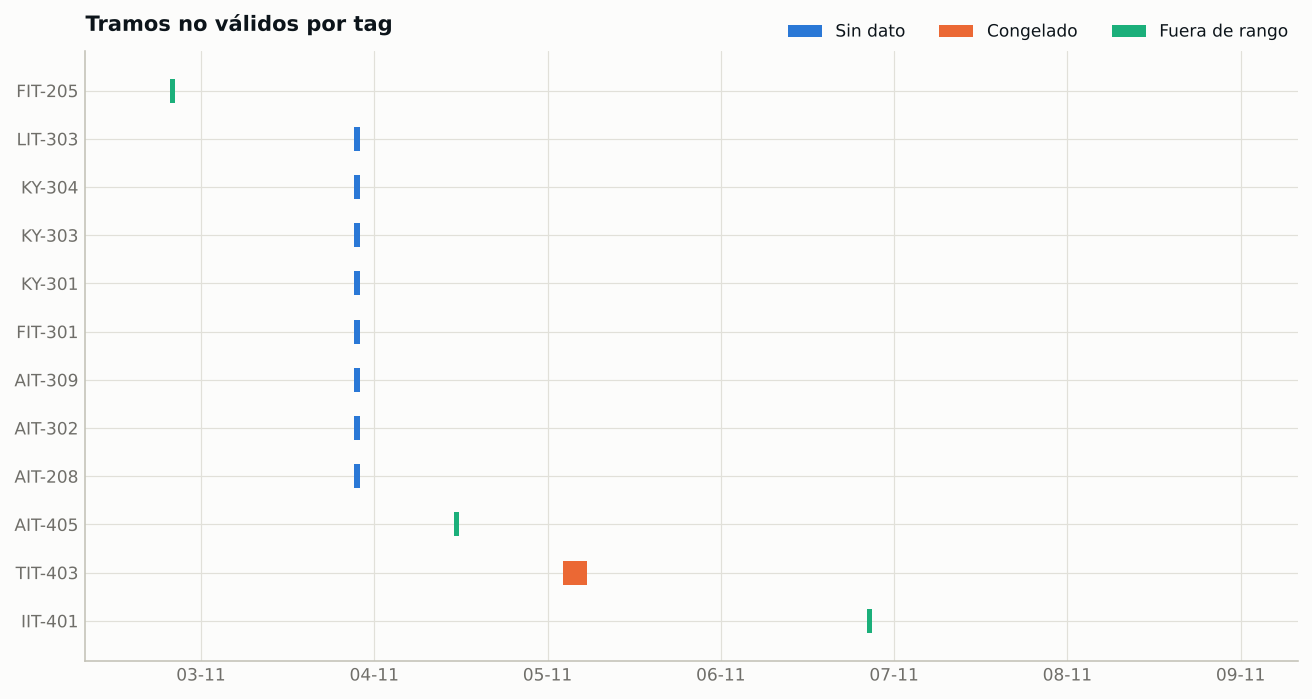

In [6]:
hallazgos = pd.concat(
    [tramos(sin_dato).assign(prueba='Sin dato'), tramos(fuera).assign(prueba='Fuera de rango'), tramos(congelado).assign(prueba='Congelado')],
    ignore_index=True,
)
orden = hallazgos.groupby('tag').desde.min().sort_values(ascending=False).index
fila = {tag: i for i, tag in enumerate(orden)}
fig, ax = plt.subplots(figsize=(9, 0.32 * len(orden) + 0.9))
for prueba, color in [('Sin dato', AZUL), ('Congelado', NARANJA), ('Fuera de rango', VERDE)]:
    t = hallazgos[hallazgos.prueba == prueba]
    ancho = (t.hasta - t.desde).clip(lower=pd.Timedelta('40min'))  # un minuto suelto no se vería
    ax.barh(t.tag.map(fila), ancho, left=t.desde, height=0.5, color=color, label=prueba)
ax.set_yticks(range(len(orden)), orden)
ax.set_xlim(malla[0], malla[-1])
ax.set_title('Tramos no válidos por tag')
ax.legend(ncols=3, loc='lower right', bbox_to_anchor=(1, 1), borderaxespad=0.2)
plt.show()

**Contra lo sembrado.** El generador dejó anotados los defectos que metió en el historiador. Se cruza cada uno con lo encontrado.

In [7]:
verdad = json.loads((DATOS / 'verdad.json').read_text(encoding='utf-8'))
sembrado = pd.DataFrame(verdad['defectos'])
sembrado[['desde', 'hasta']] = sembrado[['desde', 'hasta']].apply(pd.to_datetime)


def encontrado(d):
    if d.tipo == 'duplicado':
        return repetidas.fecha.between(d.desde, d.hasta).sum() == 2
    if d.tipo == 'filas_faltantes':
        return set(pd.date_range(d.desde, d.hasta, freq='1min')) <= set(faltantes)
    mascara = {'sin_dato': sin_dato, 'congelado': congelado, 'fuera_de_rango': fuera}[d.tipo]
    return bool(mascara.loc[d.desde : d.hasta, d.tags].all().all())


sembrado['encontrado'] = sembrado.apply(encontrado, axis=1)
sembrado['tags'] = sembrado.tags.map(lambda x: ', '.join(x[:3]) + (f' y {len(x) - 3} más' if len(x) > 3 else ''))

# falsos positivos: tramos encontrados que no calzan con ningún defecto sembrado
calza = lambda t: any((t.desde <= d.hasta) and (t.hasta >= d.desde) for d in sembrado.itertuples())
de_mas = hallazgos[~hallazgos.apply(calza, axis=1)]
print(f'Defectos sembrados encontrados: {sembrado.encontrado.sum()} de {len(sembrado)} · tramos de más: {len(de_mas)}')
sembrado[['tipo', 'tags', 'desde', 'hasta', 'nota', 'encontrado']]

Defectos sembrados encontrados: 7 de 7 · tramos de más: 0


,tipo,tags,desde,hasta,nota,encontrado
0,sin_dato,"AIT-208, FIT-301, KY-301 y 5 más",2026-11-03 21:14:00,2026-11-03 22:00:00,Pérdida de comunicación con el PLC del área 300,True
1,congelado,TIT-403,2026-11-05 02:11:00,2026-11-05 05:30:00,El transmisor repite el último valor,True
2,fuera_de_rango,FIT-205,2026-11-02 19:41:00,2026-11-02 19:41:00,Valor 9999,True
3,fuera_de_rango,AIT-405,2026-11-04 11:05:00,2026-11-04 11:05:00,Valor -1,True
4,fuera_de_rango,IIT-401,2026-11-06 20:17:00,2026-11-06 20:17:00,Valor 655.35,True
5,duplicado,,2026-11-03 22:01:00,2026-11-03 22:02:00,Dos filas reenviadas tras la reconexión,True
6,filas_faltantes,,2026-11-08 06:20:00,2026-11-08 06:31:00,Reinicio del servidor del historiador,True


Para el resto del cuaderno se trabaja con `h`: sin filas repetidas, con la malla completa de minutos y con lo no válido marcado como vacío. No se rellena nada.

In [8]:
h = h.mask(fuera | congelado)
print(f'Celdas válidas: {100 * h.notna().values.mean():.2f} %')

Celdas válidas: 99.76 %


## 3. Qué le pasó a la planta

Cuatro variables bastan para ver la semana: el cobre que llega desde las pilas, la corriente de la nave, la temperatura del electrolito y el cátodo producido. Las líneas verticales son los disparos anotados en la bitácora.

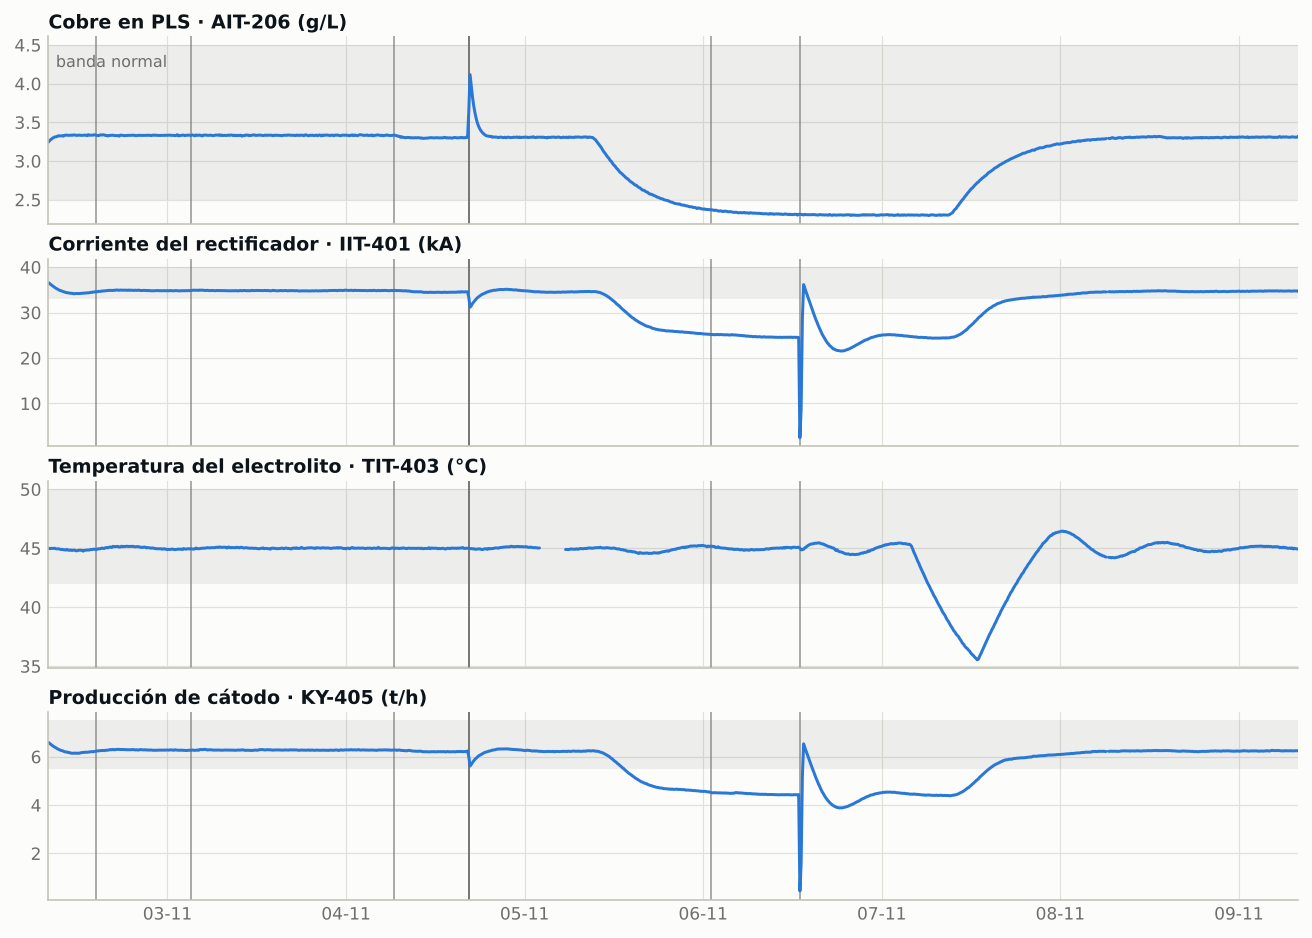

,fecha,mensaje
0,2026-11-02 14:20:00,CV-101 disparado: cordón de emergencia
1,2026-11-03 03:10:00,P-201A disparado: sobrecorriente
2,2026-11-04 06:24:22,"M-103 disparado: vibración muy alta (> 8,9 mm/s)"
3,2026-11-04 16:30:00,Interruptor MCC-200 abierto por protección
4,2026-11-04 16:30:01,P-201B disparado: sin tensión en MCC-200
5,2026-11-04 16:30:01,P-202A disparado: sin tensión en MCC-200
6,2026-11-06 01:00:00,Racha de cortocircuitos en la nave
7,2026-11-06 13:00:00,RT-401 disparado: falla de refrigeración del transformador


In [9]:
bitacora = pd.read_csv(DATOS / 'bitacora.csv', parse_dates=['fecha'])
disparos = bitacora[bitacora.clase == 'trip']

ver = ['AIT-206', 'IIT-401', 'TIT-403', 'KY-405']
media10 = h[ver].resample('10min').mean()
fig, ejes = plt.subplots(len(ver), 1, figsize=(9, 6.4), sharex=True)
for ax, tag in zip(ejes, ver):
    ax.axhspan(tags.normal_min[tag], tags.normal_max[tag], color=TENUE, alpha=0.10, lw=0)
    for f in disparos.fecha:
        ax.axvline(f, color=TENUE, lw=0.8, alpha=0.7)
    ax.plot(media10.index, media10[tag], color=AZUL)
    ax.set_title(f'{tags.descripcion[tag]} · {tag} ({tags.unidad[tag]})', fontsize=9.5, pad=4)
    ax.margins(x=0)
ejes[0].annotate('banda normal', (media10.index[6], tags.normal_max['AIT-206']), xytext=(0, -11), textcoords='offset points', fontsize=8, color=TENUE)
plt.show()

disparos[['fecha', 'mensaje']].reset_index(drop=True)

**Lectura.** El cobre en el PLS cae desde el jueves 5 y vuelve el sábado 7: es un cambio de mineral, no un disparo, y arrastra a la corriente y a la producción durante dos días. La temperatura baja el sábado 7 por la madrugada sin que la bitácora anote ninguna falla hasta que mantenimiento repara el intercambiador. El disparo del rectificador del viernes 6 se ve como un corte breve.

**Una comprobación física.** La ley de Faraday fija cuánto cobre deposita la corriente: 1,1855 g por ampere-hora y por celda, por la eficiencia de corriente. Si las unidades y los tags están bien, el cátodo medido tiene que calzar con ese cálculo.

In [10]:
CELDAS = 160
faraday = h['IIT-401'] * 1.1855 * CELDAS / 1000 * h['KY-406'] / 100  # t/h
con_corriente = h['IIT-401'] > 5
diferencia = (100 * (h['KY-405'] - faraday) / faraday)[con_corriente]
print(f'Cátodo medido contra Faraday: mediana {diferencia.median():+.2f} %, 90 % de los minutos dentro de ±{diferencia.abs().quantile(0.9):.1f} %')

Cátodo medido contra Faraday: mediana +0.00 %, 90 % de los minutos dentro de ±0.6 %


El cierre de turno resume lo mismo en toneladas. La línea es el plan.

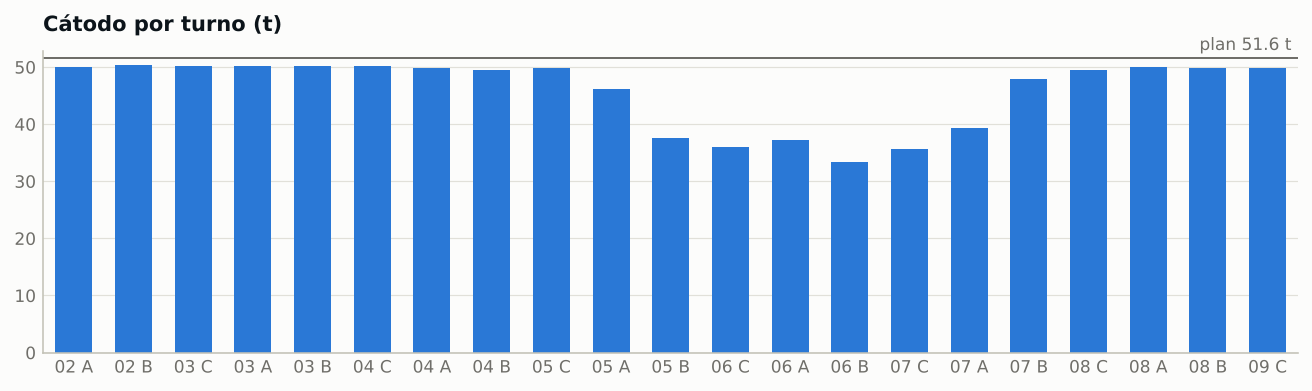

Semana: 962 t de 1084 t planificadas (89 %)
Bajo el plan: 121 t. En los 7 turnos con mineral distinto: 96 t (79 %)


In [11]:
turnos = pd.read_csv(DATOS / 'turnos.csv', parse_dates=['fecha_cierre'])
etiqueta = turnos.fecha_cierre.sub(pd.Timedelta('1min')).dt.strftime('%d') + ' ' + turnos.turno
fig, ax = plt.subplots(figsize=(9, 2.6))
ax.bar(etiqueta, turnos.catodo_t, width=0.62, color=AZUL)
ax.axhline(turnos.plan_t.iloc[0], color=TENUE, lw=1)
ax.annotate(f'plan {turnos.plan_t.iloc[0]:.1f} t', (len(turnos) - 0.6, turnos.plan_t.iloc[0]), xytext=(0, 4), textcoords='offset points', ha='right', fontsize=8.5, color=TENUE)
ax.set_title('Cátodo por turno (t)')
ax.grid(axis='x', visible=False)
ax.margins(x=0.01)
plt.show()

print(f'Semana: {turnos.catodo_t.sum():.0f} t de {turnos.plan_t.sum():.0f} t planificadas ({100 * turnos.catodo_t.sum() / turnos.plan_t.sum():.0f} %)')

# ¿Dónde se perdió? Turnos en que el cobre del PLS estuvo bajo su banda normal (mineral distinto) contra el resto.
inicio_turno = turnos.fecha_cierre - pd.Timedelta('8h')
cobre_turno = [h['AIT-206'].loc[a:b].mean() for a, b in zip(inicio_turno, turnos.fecha_cierre)]
mineral_distinto = np.array(cobre_turno) < 3.0
falta = turnos.plan_t - turnos.catodo_t
bajo_plan = falta.sum()
por_mineral = falta[mineral_distinto].sum()
print(f'Bajo el plan: {bajo_plan:.0f} t. En los {mineral_distinto.sum()} turnos con mineral distinto: {por_mineral:.0f} t ({100 * por_mineral / bajo_plan:.0f} %)')

## 4. Alarmas: ayudan o estorban

La norma ISA-18.2 da valores de referencia para saber si un operador puede atender lo que el sistema le anuncia. Se calculan sobre el registro de alarmas de la semana.

In [12]:
alarmas = pd.read_csv(DATOS / 'alarmas.csv', parse_dates=['fecha'])
activas = alarmas[alarmas.evento == 'ACTIVA']
ventanas = pd.date_range(malla[0], malla[-1], freq='10min')
por_10min = activas.set_index('fecha').resample('10min').size().reindex(ventanas, fill_value=0)

# repique: la misma alarma se activa 3 veces o más en un minuto
veces_1min = activas.set_index('fecha').groupby('alarma').alarma.rolling('60s').count()
repican = veces_1min[veces_1min >= 3].index.get_level_values(0).unique().tolist()

# alarmas pegadas: activas más de 24 h seguidas
fin = alarmas[alarmas.evento == 'NORMALIZA'].groupby('alarma').fecha.apply(list)
dura = activas.apply(lambda a: min([f for f in fin.get(a.alarma, []) if f >= a.fecha], default=malla[-1]) - a.fecha, axis=1)

indicadores = pd.DataFrame(
    [
        ['Alarmas por 10 min, promedio', round(por_10min.mean(), 2), 'cerca de 1 es aceptable; 2 es el máximo manejable'],
        ['Máximo en 10 min', int(por_10min.max()), '10 o menos'],
        ['Ventanas de 10 min con más de 10 alarmas', f'{100 * (por_10min > 10).mean():.2f} %', 'menos de 1 %'],
        ['Alarmas que repican', len(repican), 'ninguna'],
        ['Alarmas activas más de 24 h', int((dura > pd.Timedelta('24h')).sum()), 'menos de 5 por día'],
        ['Prioridad 1 · 2 · 3', ' · '.join(f'{100 * (activas.prioridad == p).mean():.0f} %' for p in (1, 2, 3)), 'cerca de 5 % · 15 % · 80 %'],
    ],
    columns=['indicador', 'esta semana', 'referencia ISA-18.2'],
).set_index('indicador')
pegadas = activas[dura > pd.Timedelta('24h')].assign(horas=(dura.dt.total_seconds() / 3600).round(0))
indicadores

,esta semana,referencia ISA-18.2
indicador,,
"Alarmas por 10 min, promedio",0.05,cerca de 1 es aceptable; 2 es el máximo manejable
Máximo en 10 min,15,10 o menos
Ventanas de 10 min con más de 10 alarmas,0.10 %,menos de 1 %
Alarmas que repican,2,ninguna
Alarmas activas más de 24 h,1,menos de 5 por día
Prioridad 1 · 2 · 3,16 % · 36 % · 48 %,cerca de 5 % · 15 % · 80 %


La alarma que estuvo activa más de un día:

In [13]:
pegadas[['fecha', 'alarma', 'descripcion', 'horas']]

,fecha,alarma,descripcion,horas
91,2026-11-05 22:55:24,AIT-206.L,Cobre bajo en PLS,36.0


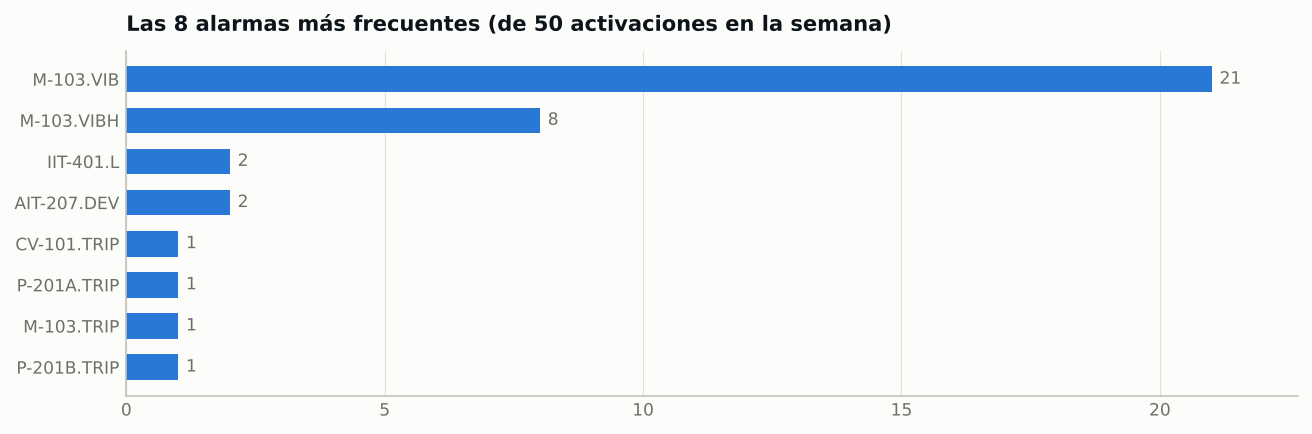

In [14]:
conteo = activas.alarma.value_counts().head(8).sort_values()
fig, ax = plt.subplots(figsize=(9, 2.9))
ax.barh(conteo.index, conteo.values, height=0.62, color=AZUL)
for y, v in enumerate(conteo.values):
    ax.annotate(str(v), (v, y), xytext=(4, 0), textcoords='offset points', va='center', fontsize=8.5, color=TENUE)
ax.set_title(f'Las 8 alarmas más frecuentes (de {len(activas)} activaciones en la semana)')
ax.grid(axis='y', visible=False)
ax.set_xlim(0, conteo.max() * 1.08)
plt.show()

**Lectura.** En promedio la planta anuncia poco, pero casi toda la carga viene de una sola fuente: las alarmas de vibración del tambor M-103, que repican cuando el valor cruza el límite ida y vuelta. Se puede medir cuánto bajaría con un retardo de 60 segundos antes de volver a anunciar.

In [15]:
separadas = activas.groupby('alarma').fecha.diff().fillna(pd.Timedelta('1D')) > pd.Timedelta('60s')
antes, despues = activas.alarma.value_counts(), activas[separadas].alarma.value_counts()
comparacion = pd.DataFrame({'activaciones': antes, 'con retardo de 60 s': despues}).loc[repican]
print(f'Total de la semana: {len(activas)} → {int(separadas.sum())} activaciones')
comparacion

Total de la semana: 50 → 28 activaciones


,activaciones,con retardo de 60 s
alarma,,
M-103.VIB,21,5
M-103.VIBH,8,2


## 5. Vibraciones: cuánto aviso da la tendencia

El monitoreo de condición entrega una lectura cada 5 minutos por motor. Primero, dónde está cada equipo respecto de las zonas de ISO 20816-3 (A: recién puesto en marcha; B: operación sin restricción; C: no apto para operar en forma continua; D: daño).

In [16]:
vib = pd.read_csv(DATOS / 'vibraciones.csv', parse_dates=['fecha'])
equipos = pd.read_csv(DATOS / 'equipos.csv', index_col='equipo')
andando = vib[vib.estado == 'RUN']


def zona(v, eq):
    return 'ABCD'[int(np.searchsorted(equipos.loc[eq, ['limite_ab', 'limite_bc', 'limite_cd']].astype(float).values, v))]


resumen = andando.groupby('equipo').vibracion_mm_s.agg(horas=lambda s: round(len(s) / 12), mediana='median', maximo='max')
resumen['zona habitual'] = [zona(v, e) for e, v in resumen.mediana.items()]
resumen['peor zona'] = [zona(v, e) for e, v in resumen.maximo.items()]
resumen.join(equipos[['descripcion', 'potencia_kw']]).sort_values('maximo', ascending=False).head(6)

,horas,mediana,maximo,zona habitual,peor zona,descripcion,potencia_kw
equipo,,,,,,,
M-103,167,1.725,8.583,A,D,Tambor aglomerador AD-101,450
P-202A,168,2.354,2.410,B,B,Bomba de PLS a SX A,750
P-201A,19,2.362,2.410,B,B,Bomba de riego A,900
P-201B,149,2.362,2.409,B,B,Bomba de riego B (respaldo),900
P-202B,111,2.302,2.349,B,B,Bomba de PLS a SX B (respaldo),750
CV-101,166,2.228,2.289,A,A,Correa de alimentación,315


Solo el tambor M-103 salió de la zona B. Un detector simple para todos los motores: la pendiente de la última hora, por mínimos cuadrados. Avisa si supera 0,25 mm/s por hora en un motor que lleva al menos dos horas andando (así no confunde una partida con una falla).

In [17]:
v = vib.pivot(index='fecha', columns='equipo', values='vibracion_mm_s')
marcha = vib.pivot(index='fecha', columns='equipo', values='estado').eq('RUN')
estable = marcha.rolling(24).sum() == 24  # 24 lecturas = 2 h seguidas andando

x = np.arange(12) * 5 / 60  # horas
x = x - x.mean()
pendiente = v.where(marcha).rolling(12).apply(lambda y: (x * (y - y.mean())).sum() / (x**2).sum(), raw=True)
aviso = (pendiente > 0.25) & estable
inicio = aviso & ~aviso.shift(1, fill_value=False)
avisos = inicio.stack().loc[lambda s: s].index.to_frame(index=False).rename(columns={'fecha': 'aviso de tendencia'})
avisos

,aviso de tendencia,equipo
0,2026-11-04 02:05:00,M-103
1,2026-11-08 10:05:00,M-103


Dos avisos en la semana, los dos en M-103, ninguno en los otros quince motores. Ahora el pronóstico: con cada lectura nueva se ajusta un crecimiento exponencial a la última hora y se calcula a qué hora cruzaría el límite de disparo.

In [18]:
m103 = v['M-103'].where(marcha['M-103'])
lim_c, lim_d = equipos.loc['M-103', ['limite_bc', 'limite_cd']].astype(float)
lim_disparo = 1.25 * lim_d


def pronostico(ahora, limite, lecturas=12):
    """Hora en que la vibración cruzaría `limite`, con lo visto hasta `ahora`."""
    base = m103.loc[: ahora - pd.Timedelta('3h')].tail(144).median()  # nivel sano: mediana de 12 h
    ventana = m103.loc[:ahora].tail(lecturas)
    horas = (ventana.index - ahora).total_seconds() / 3600
    tasa, nivel = np.polyfit(horas, np.log((ventana - base).clip(lower=1e-3)), 1)
    return ahora + pd.Timedelta(hours=(np.log(limite - base) - nivel) / tasa) if tasa > 0 else pd.NaT


def hora_real(patron, desde):
    f = bitacora[bitacora.mensaje.str.contains(patron) & (bitacora.fecha >= desde)].fecha
    return f.iloc[0] if len(f) else pd.NaT


alarma_c = activas[activas.alarma == 'M-103.VIB'].fecha
filas = []
for n, t0 in enumerate(avisos['aviso de tendencia'], 1):
    disparo = hora_real('M-103 disparado', t0)
    disparo = disparo if disparo - t0 < pd.Timedelta('12h') else pd.NaT
    cruce_c = alarma_c[alarma_c >= t0].iloc[0]
    for minutos in (60, 90, 120, 180):
        ahora = t0 + pd.Timedelta(minutes=minutos)
        if ahora >= cruce_c:
            continue
        p_c, p_disp = pronostico(ahora, lim_c), pronostico(ahora, lim_disparo)
        filas.append({'episodio': n, 'pronóstico hecho a las': ahora, 'zona C: error (min)': round((p_c - cruce_c).total_seconds() / 60), 'disparo pronosticado': p_disp.round('min'), 'disparo real': disparo.round('s'), 'disparo: error (min)': round((p_disp - disparo).total_seconds() / 60) if pd.notna(disparo) else None})
evaluacion = pd.DataFrame(filas).set_index(['episodio', 'pronóstico hecho a las'])
evaluacion

zona C: error (min) disparo pronosticado  \
episodio pronóstico hecho a las                                             
1        2026-11-04 03:05:00                     -19  2026-11-04 05:40:00   
         2026-11-04 03:35:00                      -3  2026-11-04 06:11:00   
         2026-11-04 04:05:00                      -4  2026-11-04 06:07:00   
2        2026-11-08 11:05:00                      -6  2026-11-08 13:59:00   
         2026-11-08 11:35:00                      -6  2026-11-08 14:00:00   
         2026-11-08 12:05:00                       0  2026-11-08 14:15:00   

                                       disparo real  disparo: error (min)  
episodio pronóstico hecho a las                                            
1        2026-11-04 03:05:00    2026-11-04 06:24:22                 -44.0  
         2026-11-04 03:35:00    2026-11-04 06:24:22                 -14.0  
         2026-11-04 04:05:00    2026-11-04 06:24:22                 -18.0  
2        2026-11-08 11:05:00                    NaT                   NaN  
         2026-11-08 11:35:00                    NaT                   NaN  
         2026-11-08 12:05:00                    NaT                   NaN

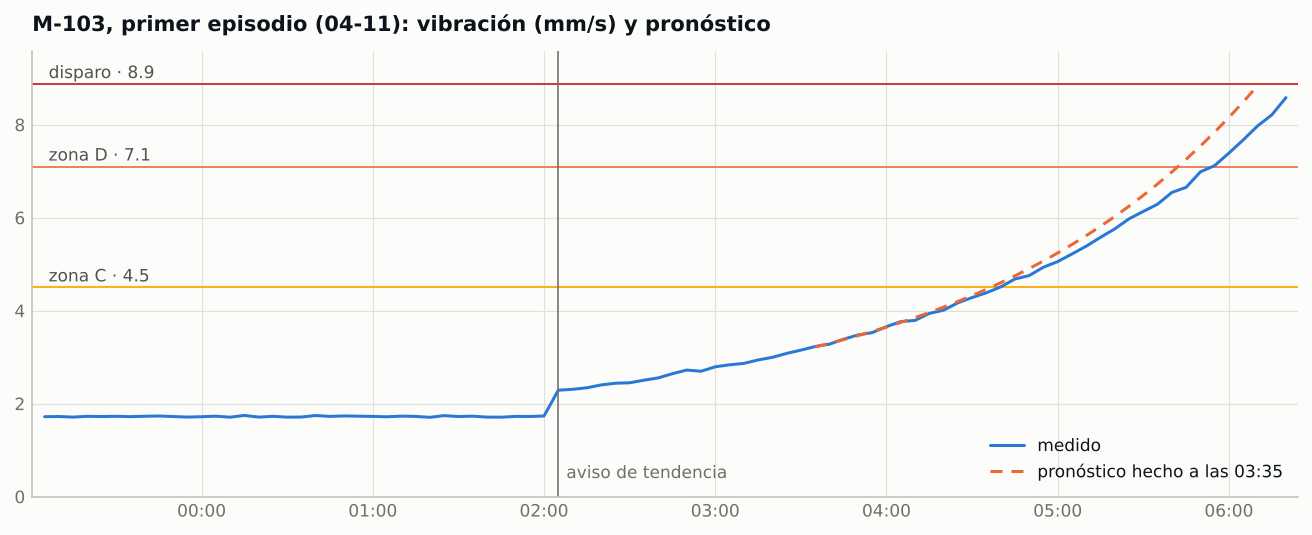

Aviso de tendencia: 4.3 h antes del disparo. La alarma de zona C llegó 155 min después del aviso.


In [19]:
t0 = avisos['aviso de tendencia'].iloc[0]
disparo = hora_real('M-103 disparado', t0)
tramo = m103.loc[t0 - pd.Timedelta('3h') : disparo]
ahora = t0 + pd.Timedelta('90min')
base = m103.loc[: ahora - pd.Timedelta('3h')].tail(144).median()
ventana = m103.loc[:ahora].tail(12)
tasa, nivel = np.polyfit((ventana.index - ahora).total_seconds() / 3600, np.log(ventana - base), 1)
futuro = pd.date_range(ahora, pronostico(ahora, lim_disparo), freq='5min')

fig, ax = plt.subplots(figsize=(9, 3.6))
for limite, color, nombre in [(lim_c, ALERTA, 'zona C'), (lim_d, GRAVE, 'zona D'), (lim_disparo, CRITICO, 'disparo')]:
    ax.axhline(limite, color=color, lw=1)
    ax.annotate(f'{nombre} · {limite:.1f}', (tramo.index[0], limite), xytext=(2, 3), textcoords='offset points', fontsize=8.5, color=plt.rcParams['axes.labelcolor'])
ax.plot(tramo.index, tramo, color=AZUL, label='medido')
ax.plot(futuro, base + np.exp(nivel + tasa * (futuro - ahora).total_seconds() / 3600), color=NARANJA, lw=1.5, ls=(0, (4, 3)), label=f'pronóstico hecho a las {ahora:%H:%M}')
ax.axvline(t0, color=TENUE, lw=0.8)
ax.annotate('aviso de tendencia', (t0, 0.4), xytext=(4, 0), textcoords='offset points', fontsize=8.5, color=TENUE)
ax.set_ylim(0, lim_disparo * 1.08)
ax.set_title(f'M-103, primer episodio ({t0:%d-%m}): vibración (mm/s) y pronóstico')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
ax.legend(loc='lower right')
ax.margins(x=0.01)
plt.show()

antes_alarma = (alarma_c[alarma_c >= t0].iloc[0] - t0).total_seconds() / 60
print(f'Aviso de tendencia: {(disparo - t0).total_seconds() / 3600:.1f} h antes del disparo. La alarma de zona C llegó {antes_alarma:.0f} min después del aviso.')

**Lectura.** La tendencia avisa horas antes que la alarma por límite, y desde la primera hora pone el disparo dentro de un margen de menos de una hora, siempre por el lado temprano. En el segundo episodio mantenimiento cambió el rodamiento antes del disparo, así que ahí solo se puede comprobar el cruce a zona C. Son dos episodios del mismo motor y de un simulador: el método queda mostrado, no validado para una planta.

## 6. El pHmetro: se descalibró o cambió el proceso

El pH del PLS se mide en línea (AIT-207) y el laboratorio toma una muestra cada 2 horas. Un detector estadístico mira solo el sensor: compara su media de 30 minutos con la mediana de las 6 horas anteriores y avisa si se separan más de 0,015 pH durante 10 minutos seguidos. En las horas tranquilas del lunes esa diferencia nunca pasó de 0,004.

In [20]:
ph = h['AIT-207']
lab = pd.read_csv(DATOS / 'laboratorio.csv', parse_dates=['fecha']).query("analito == 'pH'").set_index('fecha').valor

corto = ph.rolling(30, min_periods=20).mean()
referencia = ph.rolling(360, min_periods=120).median().shift(60)
separacion = corto - referencia
fuera_banda = (separacion.abs() > 0.015).rolling(10).sum() == 10
inicios = fuera_banda.index[fuera_banda & ~fuera_banda.shift(1, fill_value=False)]

calibraciones = bitacora[bitacora.mensaje.str.contains('AIT-207 calibrado')].fecha
filas = []
for t in inicios:
    muestra = lab[lab.index >= t].index[0]  # primera muestra de laboratorio después del aviso
    dif = ph.loc[muestra - pd.Timedelta('5min') : muestra].mean() - lab[muestra]
    tras_calibrar = ((t - calibraciones) > pd.Timedelta(0)) & ((t - calibraciones) < pd.Timedelta('45min'))
    veredicto = 'calibración (bitácora)' if tras_calibrar.any() else 'sensor' if abs(dif) > 0.05 else 'proceso'
    filas.append({'aviso': t, 'muestra de laboratorio': muestra, 'sensor − laboratorio': round(dif, 3), 'veredicto': veredicto})
avisos_ph = pd.DataFrame(filas)
avisos_ph

,aviso,muestra de laboratorio,sensor − laboratorio,veredicto
0,2026-11-03 10:29:00,2026-11-03 11:50:00,0.216,sensor
1,2026-11-05 09:50:00,2026-11-05 09:50:00,0.001,proceso
2,2026-11-07 09:45:00,2026-11-07 09:50:00,-0.002,proceso
3,2026-11-07 17:48:00,2026-11-07 17:50:00,0.076,sensor
4,2026-11-07 23:23:00,2026-11-07 23:50:00,0.002,calibración (bitácora)


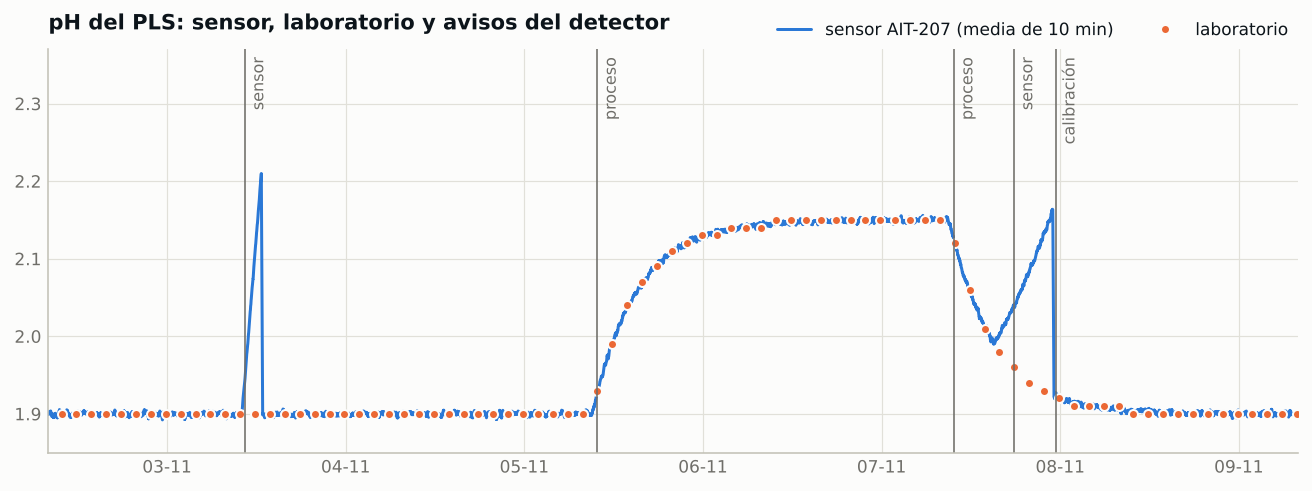

In [21]:
fig, ax = plt.subplots(figsize=(9, 3.3))
ax.plot(ph.index, ph.rolling(10, min_periods=5).mean(), color=AZUL, label='sensor AIT-207 (media de 10 min)')
ax.plot(lab.index, lab, ls='none', marker='o', ms=4.5, mfc=NARANJA, mec=plt.rcParams['axes.facecolor'], mew=1, label='laboratorio')
for a in avisos_ph.itertuples():
    ax.axvline(a.aviso, color=TENUE, lw=0.8)
    ax.annotate(a.veredicto.split(' ')[0], (a.aviso, 2.36), xytext=(3, 0), textcoords='offset points', fontsize=8, color=TENUE, rotation=90, va='top')
ax.set_ylim(1.85, 2.37)
ax.set_title('pH del PLS: sensor, laboratorio y avisos del detector')
ax.legend(loc='lower right', bbox_to_anchor=(1, 1), ncols=2, borderaxespad=0.2)
ax.margins(x=0)
plt.show()

**Contra lo sembrado.** Se compara cada aviso con lo que el generador hizo en ese momento, y con la hora en que saltó la alarma que ya trae la planta (desviación mayor a 0,15 pH contra el laboratorio).

In [22]:
fallas = pd.DataFrame(verdad['fallas'])
fallas['inicio'] = pd.to_datetime(fallas.inicio)
causa = {'ph': 'sensor', 'ph_lenta': 'sensor', 'ore': 'proceso'}
sembradas = fallas[fallas.id.isin(causa)].assign(real=lambda d: d.id.map(causa))
alarma_ph = activas[activas.alarma == 'AIT-207.DEV'].fecha

filas = []
for f in sembradas.itertuples():
    a = avisos_ph[avisos_ph.aviso >= f.inicio].iloc[0]
    al = alarma_ph[alarma_ph >= f.inicio]
    con_alarma = f.real == 'sensor' and len(al) > 0
    filas.append({'sembrado': f.nombre, 'inicio': f.inicio, 'aviso (min después)': round((a.aviso - f.inicio).total_seconds() / 60), 'alarma de planta (min después)': round((al.iloc[0] - f.inicio).total_seconds() / 60) if con_alarma else None, 'veredicto': a.veredicto, 'real': f.real})
resultado_ph = pd.DataFrame(filas)
print(f'Veredictos correctos: {(resultado_ph.veredicto == resultado_ph.real).sum()} de {len(resultado_ph)}')
resultado_ph

Veredictos correctos: 4 de 4


,sembrado,inicio,aviso (min después),alarma de planta (min después),veredicto,real
0,Deriva del pHmetro AIT-207,2026-11-03 10:00:00,29,110.0,sensor,sensor
1,Cambio de mineral,2026-11-05 09:00:00,50,NaN,proceso,proceso
2,Vuelve el mineral original,2026-11-07 09:00:00,45,NaN,proceso,proceso
3,Deriva lenta del pHmetro AIT-207,2026-11-07 15:00:00,168,410.0,sensor,sensor


**Lectura.** El detector solo no distingue un sensor que deriva de un mineral distinto: en los dos casos el valor se mueve. La muestra de laboratorio lo resuelve. Si el sensor y el laboratorio coinciden, cambió el proceso; si no, es el instrumento. En la deriva rápida el aviso llega bastante antes que la alarma de planta. En la lenta también, pero ahí la ganancia viene sobre todo de usar un umbral más fino contra el laboratorio (0,05 en vez de 0,15 pH). Ese umbral se eligió mirando esta semana; habría que probarlo con otra.

## 7. Anticipar la producción cuatro horas antes

El cobre tarda horas en pasar de las pilas a la nave, así que lo que se ve aguas arriba debería anticipar el cátodo. El objetivo es la producción media de la hora que termina cuatro horas después. La vara es la persistencia: suponer que en cuatro horas se producirá lo mismo que ahora. Se entrena con lo anterior a un corte en el tiempo y se evalúa con lo posterior.

**Primer intento: con la semana de este cuaderno.**

In [23]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ENTRADAS = ['AIT-206', 'FIT-205', 'AIT-208', 'KY-303', 'KY-304', 'AIT-302', 'AIT-405', 'TIT-403', 'AIT-407', 'IIT-401', 'KY-406', 'KY-405']


def preparar(m10, horas):
    """Tabla para pronosticar: entradas de ahora, su cambio reciente, el objetivo a `horas` y la persistencia."""
    X = m10[ENTRADAS].copy()
    for tag in ('AIT-206', 'KY-304', 'AIT-405'):
        X[tag + ' cambio 2 h'] = m10[tag] - m10[tag].shift(12)
        X[tag + ' cambio 6 h'] = m10[tag] - m10[tag].shift(36)
    ahora = m10['KY-405'].rolling(6).mean()
    return X.assign(objetivo=ahora.shift(-6 * horas), persistencia=ahora).dropna()


def evaluar(tabla, corte, horas):
    """Entrena antes del corte y mide después, dejando un hueco igual al horizonte."""
    entrena, prueba = tabla.loc[:corte], tabla.loc[pd.Timestamp(corte) + pd.Timedelta(hours=horas) :]
    Xe, Xp = entrena.drop(columns=['objetivo', 'persistencia']), prueba.drop(columns=['objetivo', 'persistencia'])
    ridge = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 12))).fit(Xe, entrena.objetivo)
    boosting = HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=300, random_state=0).fit(Xe, entrena.objetivo)
    return prueba.assign(ridge=ridge.predict(Xp), boosting=boosting.predict(Xp)), len(entrena)


def error(p, columna, filas=slice(None)):
    return float((p.objetivo - p[columna]).abs()[filas].mean())


filas = []
for corte in ('2026-11-06 08:00', '2026-11-07 00:00'):
    p, n = evaluar(preparar(h.resample('10min').mean(), 4), corte, 4)
    filas.append({'corte': corte, 'horas de entrenamiento': round(n / 6), 'persistencia': error(p, 'persistencia'), 'regresión ridge': error(p, 'ridge'), 'gradient boosting': error(p, 'boosting')})
una_semana = pd.DataFrame(filas).set_index('corte')
una_semana

,horas de entrenamiento,persistencia,regresión ridge,gradient boosting
corte,,,,
2026-11-06 08:00,85,0.235,0.343,0.342
2026-11-07 00:00,101,0.166,0.559,0.409


No alcanza: ninguno de los dos modelos le gana a la persistencia, en ninguno de los dos cortes. La semana trae un solo cambio de mineral: no hay de dónde aprender cómo responde la planta.

**Segundo intento: con ocho semanas.** El mismo motor se corrió ocho semanas con 15 cambios de mineral a intervalos irregulares (`herramientas/genera_largo.js`). El archivo trae medias de 10 minutos. Se entrena con las seis primeras semanas y se prueba con las dos últimas, a 2, 4 y 8 horas. Aparte se mide el error en los momentos que importan: cuando la producción cambia más de 0,3 t/h dentro del horizonte.

In [24]:
largo = pd.read_csv(DATOS / 'historiador_8_semanas.csv', parse_dates=['fecha'], index_col='fecha')
corte_largo = largo.index[0] + pd.Timedelta(weeks=6)

filas, pruebas = [], {}
for horas in (2, 4, 8):
    p, n = evaluar(preparar(largo, horas), corte_largo, horas)
    cambia = (p.objetivo - p.persistencia).abs() > 0.3
    pruebas[horas] = p
    filas.append({
        'horizonte (h)': horas,
        'persistencia': error(p, 'persistencia'), 'regresión ridge': error(p, 'ridge'), 'gradient boosting': error(p, 'boosting'),
        'horas con cambio': round(cambia.sum() / 6),
        'persistencia, con cambio': error(p, 'persistencia', cambia), 'ridge, con cambio': error(p, 'ridge', cambia),
    })
ocho_semanas = pd.DataFrame(filas).set_index('horizonte (h)')
print(f'Entrenamiento: {largo.index[0]:%d-%m} a {corte_largo:%d-%m} · prueba: hasta {largo.index[-1]:%d-%m} · error absoluto medio en t/h')
ocho_semanas

Entrenamiento: 07-09 a 19-10 · prueba: hasta 02-11 · error absoluto medio en t/h


,persistencia,regresión ridge,gradient boosting,horas con cambio,"persistencia, con cambio","ridge, con cambio"
horizonte (h),,,,,,
2,0.038,0.029,0.047,6,1.069,0.577
4,0.058,0.033,0.081,14,0.728,0.271
8,0.094,0.083,0.269,40,0.541,0.264


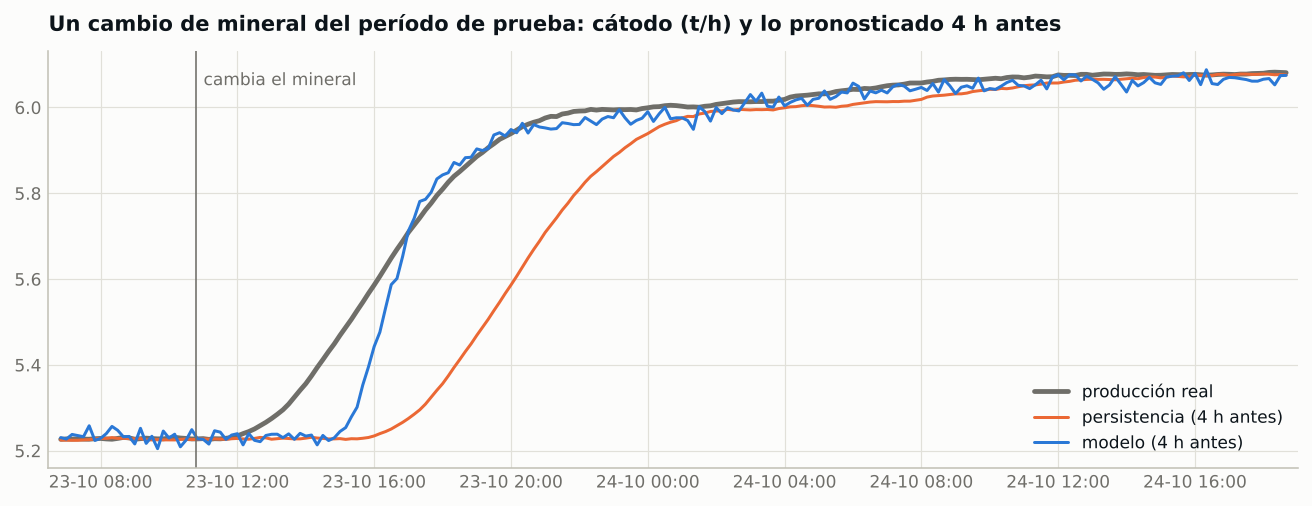

A 4 h, cuando la producción cambia: persistencia 0.73 t/h, modelo 0.27 t/h (63 % menos error)


In [25]:
p4 = pruebas[4]
a_la_hora = lambda col: p4[col].set_axis(p4.index + pd.Timedelta('4h'))  # cada pronóstico, puesto en la hora que pronostica
real = a_la_hora('objetivo')
# el cambio de mineral más grande del período de prueba, según el registro de la campaña
eventos = pd.read_csv(DATOS / 'historiador_8_semanas_eventos.csv', parse_dates=['fecha']).query("evento == 'mineral'")
eventos['salto'] = eventos.factor_mineral.diff().abs()
cambio = eventos[eventos.fecha > corte_largo + pd.Timedelta('1D')].sort_values('salto').iloc[-1]
tramo = slice(cambio.fecha - pd.Timedelta('4h'), cambio.fecha + pd.Timedelta('32h'))

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(real[tramo].index, real[tramo], color=TENUE, lw=2.4, label='producción real')
ax.plot(a_la_hora('persistencia')[tramo].index, a_la_hora('persistencia')[tramo], color=NARANJA, label='persistencia (4 h antes)')
ax.plot(a_la_hora('ridge')[tramo].index, a_la_hora('ridge')[tramo], color=AZUL, label='modelo (4 h antes)')
ax.axvline(cambio.fecha, color=TENUE, lw=0.8)
ax.annotate('cambia el mineral', (cambio.fecha, real[tramo].max()), xytext=(4, 0), textcoords='offset points', va='top', fontsize=8.5, color=TENUE)
ax.set_title('Un cambio de mineral del período de prueba: cátodo (t/h) y lo pronosticado 4 h antes')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d-%m %H:%M'))
ax.legend(loc='best')
ax.margins(x=0.01)
plt.show()

mejora = 100 * (1 - ocho_semanas.loc[4, 'ridge, con cambio'] / ocho_semanas.loc[4, 'persistencia, con cambio'])
print(f"A 4 h, cuando la producción cambia: persistencia {ocho_semanas.loc[4, 'persistencia, con cambio']:.2f} t/h, modelo {ocho_semanas.loc[4, 'ridge, con cambio']:.2f} t/h ({mejora:.0f} % menos error)")

**Lectura.** Con ocho semanas, sí. La regresión le gana a la persistencia en los tres horizontes, y la diferencia grande está donde sirve: cuando cambia el mineral, el error a cuatro horas baja a menos de la mitad. Eso alcanza para avisar al turno que viene que la producción va a caer, y cuánto. Un disparo del rectificador no se anticipa con estos datos: ahí ningún método sirve. El gradient boosting, más flexible, pierde contra el modelo simple: con estos datos, más complejidad no ayuda. Y el primer intento deja la otra lección: una semana no basta; hace falta historia con varios cambios.

## Qué cambia con el análisis

Las cifras de cada caso, tomadas de las variables que calculó el cuaderno.

In [26]:
min_alarma_disparo = (disparo - alarma_c[alarma_c >= t0].iloc[0]).total_seconds() / 60
sensor = resultado_ph[resultado_ph.real == 'sensor']
contraste = pd.DataFrame(
    [
        ['Datos confiables', f'{int(sin_dato.values.sum() + fuera.values.sum() + congelado.values.sum())} celdas malas sin marcar', f'{int(sembrado.encontrado.sum())} de {len(sembrado)} defectos encontrados, {len(de_mas)} de más'],
        ['Qué pasó en la semana', f'{bajo_plan:.0f} t bajo el plan', f'{100 * por_mineral / bajo_plan:.0f} % en turnos con mineral distinto'],
        ['Alarmas', f'{len(activas)} anuncios', f'{int(separadas.sum())} con retardo de 60 s'],
        ['Vibración', f'aviso {min_alarma_disparo / 60:.1f} h antes del disparo (alarma por límite)', f'aviso {(disparo - t0).total_seconds() / 3600:.1f} h antes (tendencia)'],
        ['pH: sensor o proceso', ' y '.join(f'{v:.0f}' for v in sensor['alarma de planta (min después)']) + ' min hasta la alarma de planta', ' y '.join(f'{v:.0f}' for v in sensor['aviso (min después)']) + ' min hasta el aviso'],
        ['Anticipar la producción', f"{ocho_semanas.loc[4, 'persistencia, con cambio']:.2f} t/h de error a 4 h cuando cambia", f"{ocho_semanas.loc[4, 'ridge, con cambio']:.2f} t/h"],
    ],
    columns=['caso de uso', 'sin el análisis', 'con el análisis'],
).set_index('caso de uso')
contraste

,sin el análisis,con el análisis
caso de uso,,
Datos confiables,580 celdas malas sin marcar,"7 de 7 defectos encontrados, 0 de más"
Qué pasó en la semana,121 t bajo el plan,79 % en turnos con mineral distinto
Alarmas,50 anuncios,28 con retardo de 60 s
Vibración,aviso 1.7 h antes del disparo (alarma por límite),aviso 4.3 h antes (tendencia)
pH: sensor o proceso,110 y 410 min hasta la alarma de planta,29 y 168 min hasta el aviso
Anticipar la producción,0.73 t/h de error a 4 h cuando cambia,0.27 t/h


Son datos de un simulador, con fallas más rápidas que las de una planta y un operador que sigue un guion. Lo que se traslada a una planta real es el procedimiento: probar los datos antes de usarlos, medir cada método contra lo que ya existe (la alarma, la muestra de laboratorio, la persistencia) y publicar también lo que no funcionó.

## Registro de la corrida

Lo necesario para repetir este cuaderno y comparar con una corrida futura: de qué datos salió, con qué versiones y qué números dio.

In [27]:
import platform

import matplotlib
import sklearn

registro = {
    'datos': {'desde': manifiesto['desde'], 'hasta': manifiesto['hasta'], 'motor_sha256': manifiesto['motor_sha256'][:12], 'historiador_sha256': manifiesto['archivos']['historiador.csv']['sha256'][:12]},
    'versiones': {'python': platform.python_version(), 'pandas': pd.__version__, 'numpy': np.__version__, 'scikit-learn': sklearn.__version__, 'matplotlib': matplotlib.__version__},
    'resultados': {
        'calidad_defectos_encontrados': f'{int(sembrado.encontrado.sum())} de {len(sembrado)}',
        'calidad_tramos_de_mas': int(len(de_mas)),
        'celdas_validas_pct': round(100 * h.notna().values.mean(), 2),
        'catodo_semana_t': round(float(turnos.catodo_t.sum()), 1),
        'alarmas_por_10min': round(float(por_10min.mean()), 2),
        'alarmas_que_repican': repican,
        'vibracion_avisos': len(avisos),
        'vibracion_error_disparo_min': evaluacion['disparo: error (min)'].dropna().astype(int).tolist(),
        'ph_veredictos_correctos': f'{int((resultado_ph.veredicto == resultado_ph.real).sum())} de {len(resultado_ph)}',
        'baja_en_turnos_con_mineral_distinto_pct': round(float(100 * por_mineral / bajo_plan)),
        'pronostico_una_semana_gana': bool((una_semana['regresión ridge'] < una_semana['persistencia']).all()),
        'pronostico_8_semanas_error_4h': {'persistencia': round(ocho_semanas.loc[4, 'persistencia'], 3), 'ridge': round(ocho_semanas.loc[4, 'regresión ridge'], 3)},
        'pronostico_8_semanas_error_4h_con_cambio': {'persistencia': round(ocho_semanas.loc[4, 'persistencia, con cambio'], 2), 'ridge': round(ocho_semanas.loc[4, 'ridge, con cambio'], 2)},
    },
}
print(json.dumps(registro, indent=2, ensure_ascii=False))

{
  "datos": {
    "desde": "2026-11-02 08:00:00",
    "hasta": "2026-11-09 08:00:00",
    "motor_sha256": "280b343ca785",
    "historiador_sha256": "b47e0996af14"
  },
  "versiones": {
    "python": "3.13.18",
    "pandas": "3.0.5",
    "numpy": "2.5.3",
    "scikit-learn": "1.9.1",
    "matplotlib": "3.11.2"
  },
  "resultados": {
    "calidad_defectos_encontrados": "7 de 7",
    "calidad_tramos_de_mas": 0,
    "celdas_validas_pct": 99.76,
    "catodo_semana_t": 962.4,
    "alarmas_por_10min": 0.05,
    "alarmas_que_repican": [
      "M-103.VIB",
      "M-103.VIBH"
    ],
    "vibracion_avisos": 2,
    "vibracion_error_disparo_min": [
      -44,
      -14,
      -18
    ],
    "ph_veredictos_correctos": "4 de 4",
    "baja_en_turnos_con_mineral_distinto_pct": 79,
    "pronostico_una_semana_gana": false,
    "pronostico_8_semanas_error_4h": {
      "persistencia": 0.058,
      "ridge": 0.033
    },
    "pronostico_8_semanas_error_4h_con_cambio": {
      "persistencia": 0.73,
      "ri